# Gammapy Integration

`viper` includes `PWNSpectralModel`, a [gammapy](https://gammapy.org)
`SpectralModel`.

Example source: **CTA 1 (PSR J0007+7303)**.

In [1]:
import astropy.units as u
import matplotlib.pyplot as plt

from viper import PWNModel
from viper.gammapy import PWNSpectralModel
from viper.plotting import plot_model_sed

## 1. Set up the model

`PWNSpectralModel.for_cta1()` returns a model pre-loaded with CTA 1
parameters.

In [2]:
model = PWNSpectralModel.for_cta1()
print(model)

PWNSpectralModel

type      name       value      unit    error   ...    max    frozen link prior
---- ------------- ---------- ------- --------- ... --------- ------ ---- -----
               esn 1.0000e+00         0.000e+00 ... 1.000e+01   True           
               mej 6.0000e+00 solMass 0.000e+00 ... 5.000e+01   True           
             n_ism 4.0000e-01    cm-3 0.000e+00 ... 1.000e+01   True           
          distance 1.4000e+03      pc 0.000e+00 ...       nan   True           
     braking_index 2.5000e+00         0.000e+00 ... 3.990e+00   True           
            tau_sd 3.0000e+03      yr 0.000e+00 ... 1.000e+06   True           
             eta_b 1.0000e-02         0.000e+00 ... 5.000e-01   True           
             e_min 3.0000e+00     GeV 0.000e+00 ... 1.000e+02   True           
             e_max 5.0000e+05     GeV 0.000e+00 ... 1.000e+08   True           
           e_break 5.0000e+01     GeV 0.000e+00 ... 1.000e+06   True           
                p1 8.0

## 2. Evaluate

The model returns a differential photon flux $dN/dE$ and supports the
usual gammapy operations. Results are cached, so repeated calls with the
same parameters (e.g. during gammapy's numerical integration) are instant.

In [3]:
# Differential flux at a single energy
print('dN/dE(1 TeV) =', model(1 * u.TeV))

# Band-integrated photon flux, 1-10 TeV
print('Flux(1-10 TeV) =', model.integral(1 * u.TeV, 10 * u.TeV))

dN/dE(1 TeV) = [8.78905901e-13] 1 / (TeV s cm2)
Flux(1-10 TeV) = 8.581927858742999e-13 1 / (s cm2)


## 3. Broadband SED

`PWNSpectralModel` wraps a `PWNModel`.

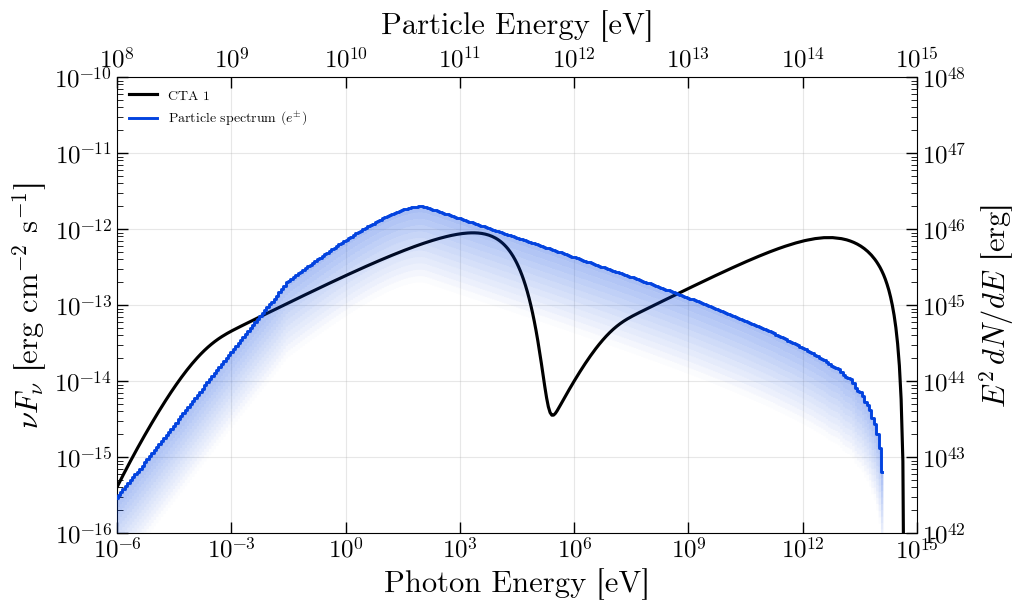

In [4]:
m = PWNModel()
m.set_pulsar('J0007+7303')          # CTA 1 pulsar: loads P, Pdot
m.distance.value      = 1.4 * u.kpc
m.esn.value           = 1e51 * u.erg
m.mej.value           = 6.0 * u.M_sun
m.n_ism.value         = 0.4 / u.cm**3
m.braking_index.value = 2.5
m.tau_sd.value        = 3000 * u.yr
m.eta_b.value         = 0.01
m.e_min.value         = 3.0 * u.GeV
m.e_max.value         = 500 * u.TeV
m.e_break.value       = 50.0 * u.GeV
m.p1.value, m.p2.value = 0.8, 2.5

result = m.run(dyn_step=10)

fig, _ = plot_model_sed(result, distance=m.distance.value, model_label='CTA 1')
plt.show()

## 4. Custom source and fitting

Every parameter is a gammapy `Parameter`. Here is how to build a model
from scratch and freeze/thaw parameters.

In [5]:
custom = PWNSpectralModel(
    period=0.0894, p_dot=1.25e-13,
    esn=1.0, mej=10.0, n_ism=0.1, distance=2000.0,
    braking_index=2.8, tau_sd=5000.0, eta_b=0.02,
    e_min=1.0, e_max=1e6, e_break=100.0,
    p1=1.4, p2=2.5,
)

# Freeze observationally-constrained parameters; thaw what you fit
custom.distance.frozen = True
custom.braking_index.frozen = True
custom.eta_b.frozen = False
custom.eta_b.min, custom.eta_b.max = 1e-4, 0.1

print(custom)

PWNSpectralModel

type      name       value      unit    error   ...    max    frozen link prior
---- ------------- ---------- ------- --------- ... --------- ------ ---- -----
               esn 1.0000e+00         0.000e+00 ... 1.000e+01   True           
               mej 1.0000e+01 solMass 0.000e+00 ... 5.000e+01   True           
             n_ism 1.0000e-01    cm-3 0.000e+00 ... 1.000e+01   True           
          distance 2.0000e+03      pc 0.000e+00 ...       nan   True           
     braking_index 2.8000e+00         0.000e+00 ... 3.990e+00   True           
            tau_sd 5.0000e+03      yr 0.000e+00 ... 1.000e+06   True           
             eta_b 2.0000e-02         0.000e+00 ... 1.000e-01  False           
             e_min 1.0000e+00     GeV 0.000e+00 ... 1.000e+02   True           
             e_max 1.0000e+06     GeV 0.000e+00 ... 1.000e+08   True           
           e_break 1.0000e+02     GeV 0.000e+00 ... 1.000e+06   True           
                p1 1.4